# Clustering des bureaux de vote
## KMeans (k=3 et k=5) | ACP | UMAP | Spectral Clustering
> Présidentielle 2022 T1 : 68 770 bureaux de vote

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.metrics import silhouette_score, pairwise_distances
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
plt.rcParams.update({'figure.dpi':120,'font.family':'DejaVu Sans',
                     'axes.grid':True,'grid.alpha':0.3,
                     'axes.spines.top':False,'axes.spines.right':False})
BASE = "/content/drive/MyDrive/Stage/"
print("Setup OK")

Mounted at /content/drive
Setup OK


## 1. Chargement

In [2]:
final_df = pd.read_csv(BASE+"resultats_t1_bureaux.csv",
                       dtype={"id_bv":str}, low_memory=False)
print(f"Base : {final_df.shape}")
CANDS = [c for c in ['MACRON_Emmanuel','LE PEN_Marine','MÉLENCHON_Jean-Luc',
    'ZEMMOUR_Éric','JADOT_Yannick','LASSALLE_Jean','PÉCRESSE_Valérie',
    'ROUSSEL_Fabien','DUPONT-AIGNAN_Nicolas','HIDALGO_Anne',
    'POUTOU_Philippe','ARTHAUD_Nathalie'] if c in final_df.columns]
scaler   = MinMaxScaler()
X_scaled = scaler.fit_transform(final_df[CANDS].values)
print(f"X_scaled : {X_scaled.shape}")
print(f"Candidats : {[c.split('_')[0] for c in CANDS]}")

Base : (68770, 20)
X_scaled : (68770, 12)
Candidats : ['MACRON', 'LE PEN', 'MÉLENCHON', 'ZEMMOUR', 'JADOT', 'LASSALLE', 'PÉCRESSE', 'ROUSSEL', 'DUPONT-AIGNAN', 'HIDALGO', 'POUTOU', 'ARTHAUD']



## 2. KMeans : Coude et silhouette (k=2 à 10)

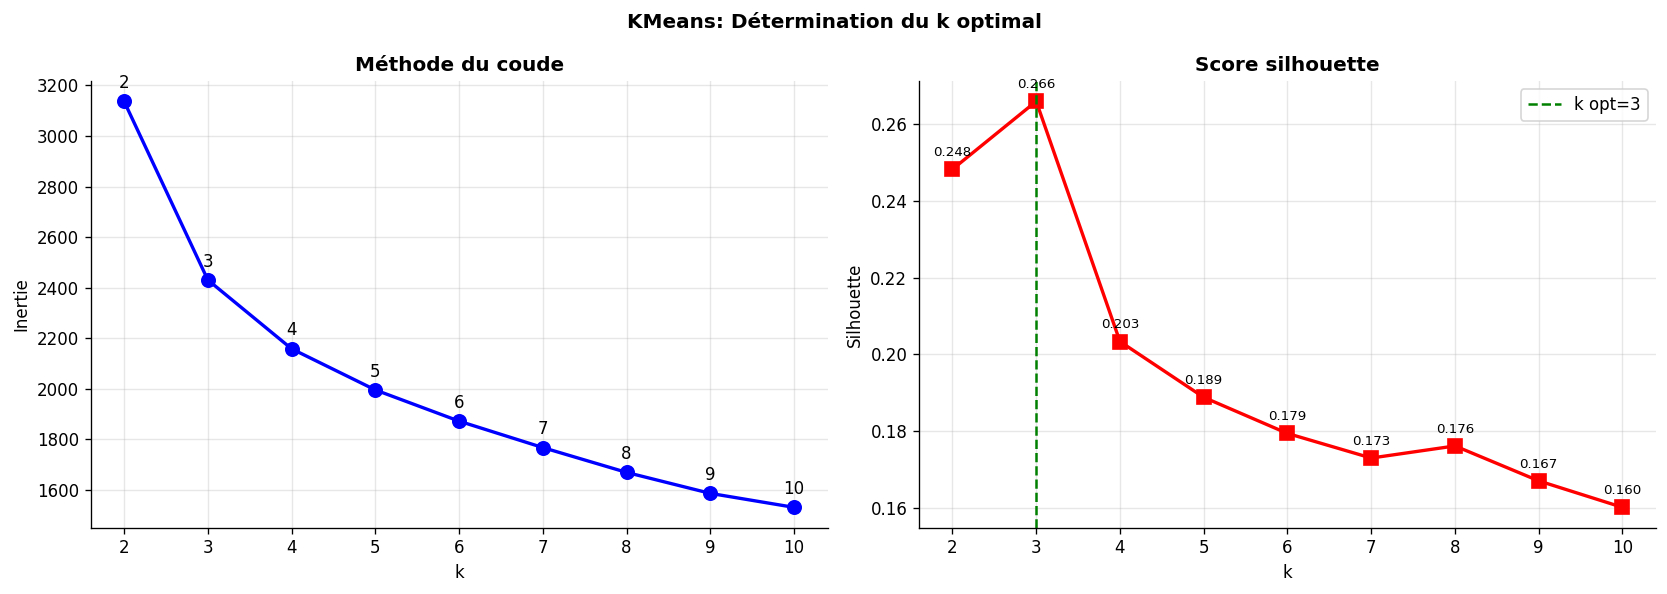

k optimal (silhouette max) : 3
silhouette k=3 : 0.266
silhouette k=5 : 0.189
Différence : 0.077


In [3]:
inertias, silhouettes = [], []
K_range = range(2, 11)
for k in K_range:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, lbl, sample_size=5000))
best_k = list(K_range)[silhouettes.index(max(silhouettes))]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(K_range, inertias, 'bo-', lw=2, markersize=8)
for k,v in zip(K_range,inertias):
    axes[0].annotate(str(k),(k,v),textcoords="offset points",xytext=(0,8),ha='center')
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertie"); axes[0].set_title("Méthode du coude",fontweight='bold')
axes[1].plot(K_range, silhouettes, 'rs-', lw=2, markersize=8)
axes[1].axvline(best_k, color='green', linestyle='--', label=f'k opt={best_k}')
for k,v in zip(K_range,silhouettes):
    axes[1].annotate(f"{v:.3f}",(k,v),textcoords="offset points",xytext=(0,8),ha='center',fontsize=8)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette"); axes[1].set_title("Score silhouette",fontweight='bold')
axes[1].legend()
plt.suptitle("KMeans: Détermination du k optimal",fontweight='bold')
plt.tight_layout(); plt.show()
print(f"k optimal (silhouette max) : {best_k}")
print(f"silhouette k=3 : {silhouettes[1]:.3f}")
print(f"silhouette k=5 : {silhouettes[3]:.3f}")
print(f"Différence : {abs(silhouettes[3]-silhouettes[1]):.3f}")

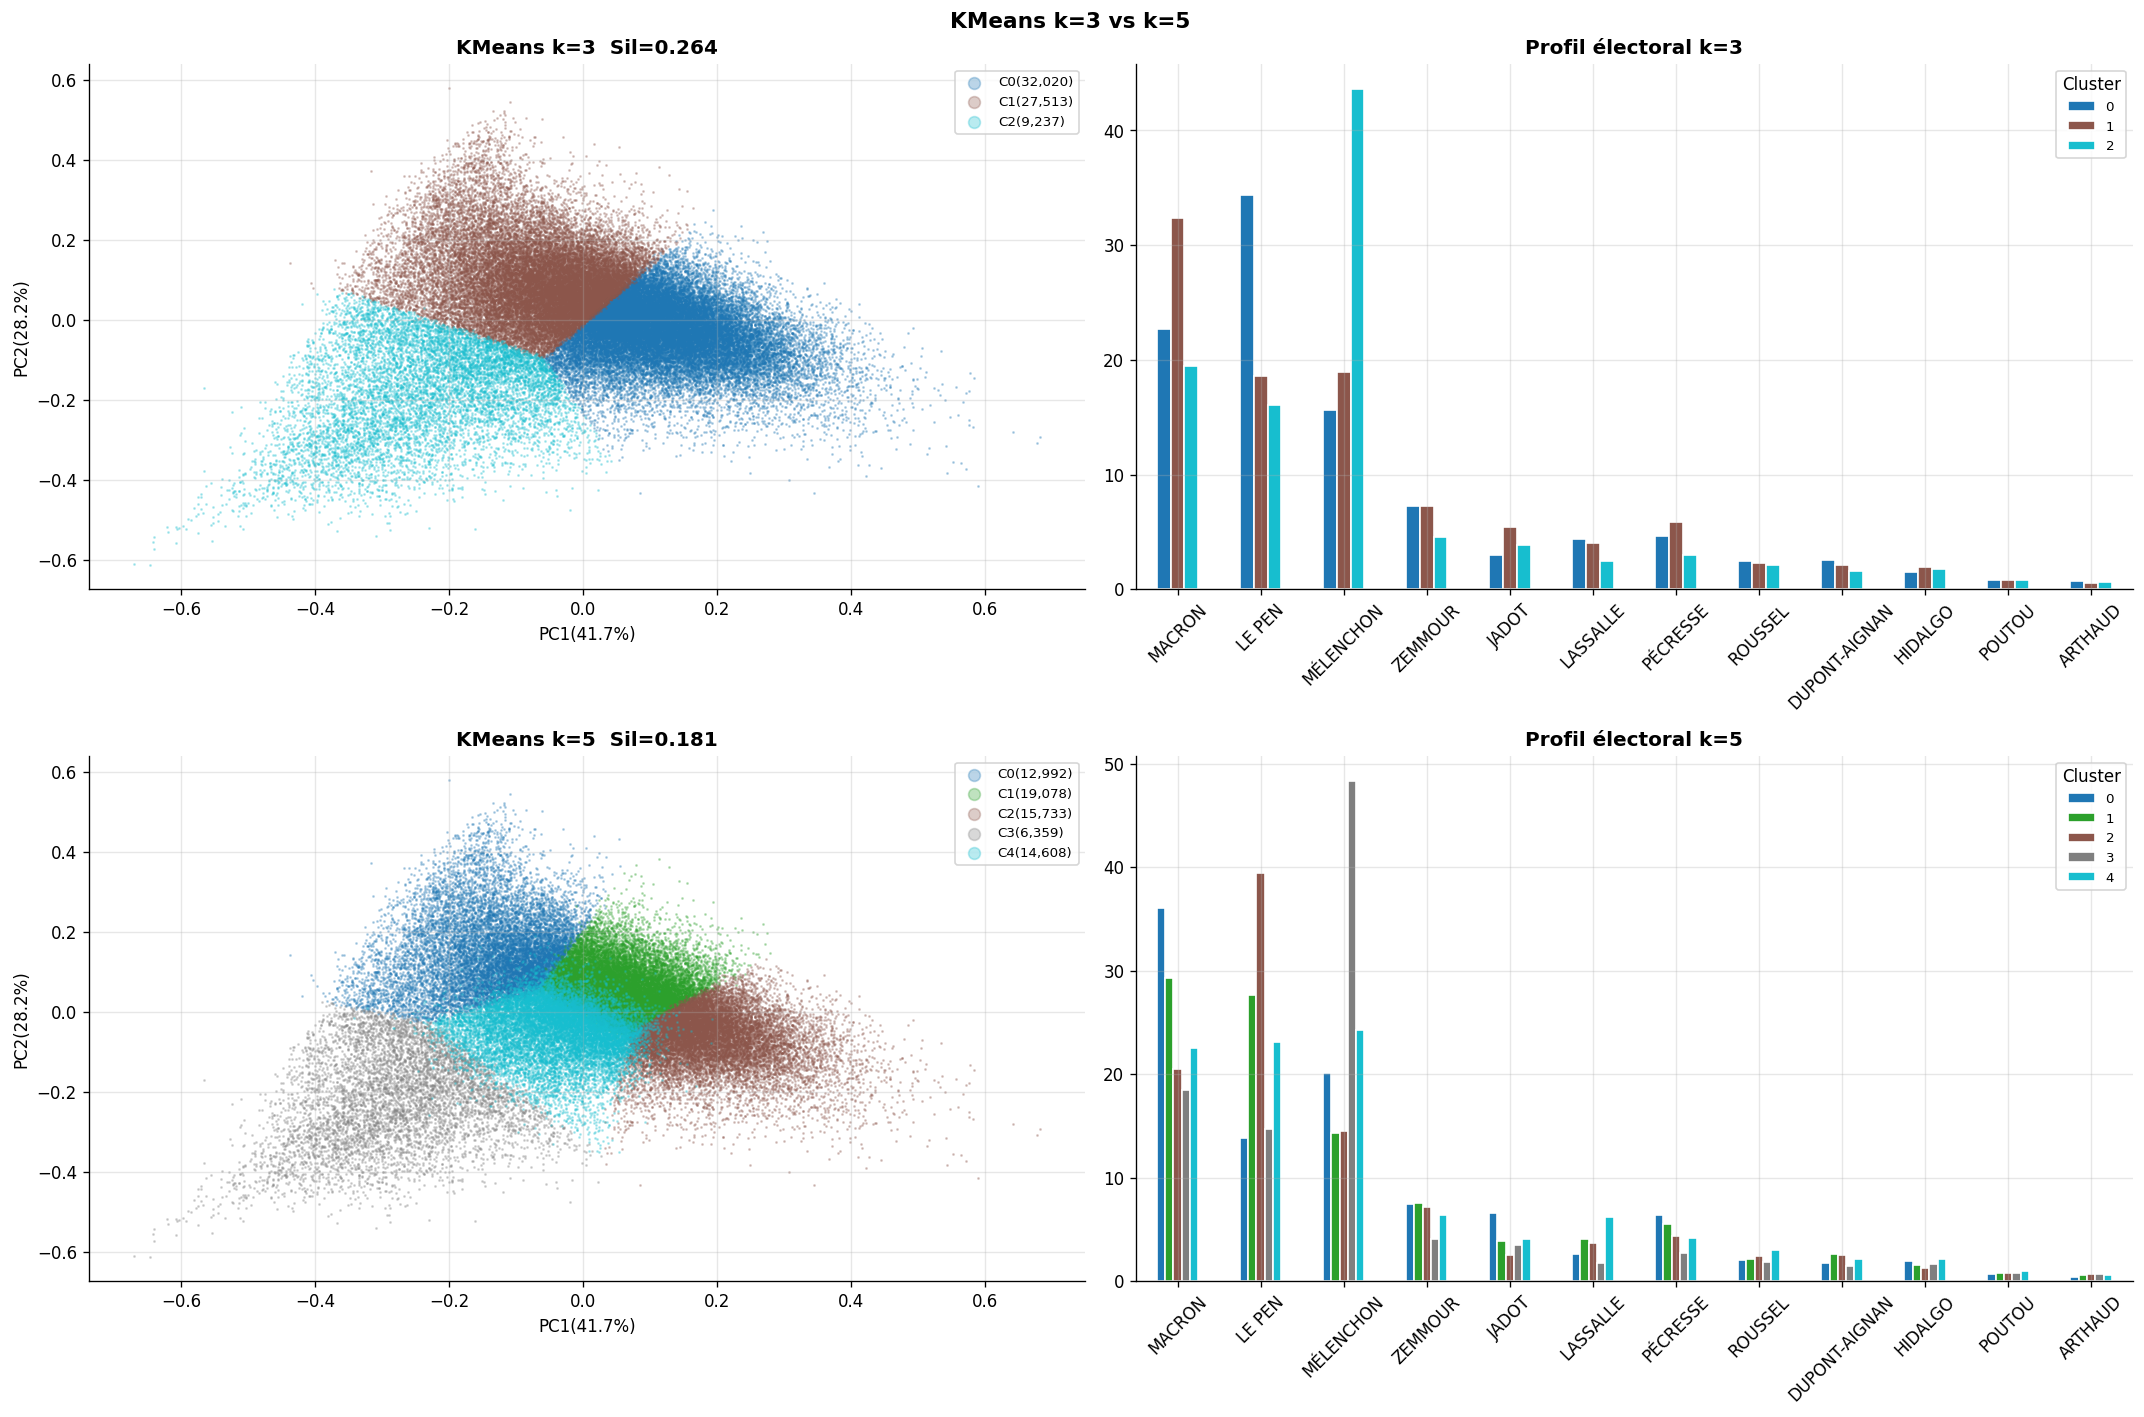

In [4]:
# KMeans k=3 et k=5 comparés sur PCA
pca2 = PCA(n_components=2)
coords = pca2.fit_transform(X_scaled)
v1,v2  = pca2.explained_variance_ratio_*100
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for row_idx, k in enumerate([3, 5]):
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lbl, sample_size=5000)
    pal = plt.cm.tab10(np.linspace(0,1,k))
    final_df[f"cluster_kmeans_k{k}"] = lbl
    ax = axes[row_idx,0]
    for cl in range(k):
        m = lbl==cl
        ax.scatter(coords[m,0],coords[m,1],c=[pal[cl]],s=0.5,alpha=0.3,label=f"C{cl}({m.sum():,})")
    ax.set_xlabel(f"PC1({v1:.1f}%)"); ax.set_ylabel(f"PC2({v2:.1f}%)")
    ax.set_title(f"KMeans k={k}  Sil={sil:.3f}",fontweight='bold')
    ax.legend(markerscale=10,fontsize=8)
    ax2 = axes[row_idx,1]
    tmp = final_df.copy(); tmp["_cl"]=lbl
    prof = tmp.groupby("_cl")[CANDS].mean()
    prof.columns=[c.split("_")[0] for c in prof.columns]
    prof.T.plot(kind='bar',ax=ax2,colormap='tab10',edgecolor='white')
    ax2.set_title(f"Profil électoral k={k}",fontweight='bold')
    ax2.tick_params(axis='x',rotation=45)
    ax2.legend(title="Cluster",bbox_to_anchor=(1,1),fontsize=8)
plt.suptitle("KMeans k=3 vs k=5 ",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()

In [5]:
# Caractérisation k=3 et k=5
for k in [3, 5]:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, lbl, sample_size=5000)
    tmp = final_df.copy(); tmp["_cl"]=lbl
    prof = tmp.groupby("_cl")[CANDS].mean()
    prof.columns=[c.split("_")[0] for c in prof.columns]
    print(f"\n{'='*60}")
    print(f"KMeans k={k} — Silhouette={sil:.3f}")
    print(f"{'='*60}")
    for cl in range(k):
        subset = final_df[lbl==cl]
        n = len(subset)
        top3 = prof.loc[cl].sort_values(ascending=False).head(3)
        t3 = ", ".join([f"{c}({v:.1f}%)" for c,v in top3.items()])
        part = subset["% Vot/Ins"].mean() if "% Vot/Ins" in subset else "?"
        deps = subset["Libellé du département"].value_counts().head(2).index.tolist() if "Libellé du département" in subset.columns else []
        print(f"  C{cl} ({n:,}, {n/len(final_df)*100:.1f}%) : {t3}")
        if part!="?": print(f"     Particip={part:.1f}%  Dépts={', '.join(deps)}")


KMeans k=3 — Silhouette=0.268
  C0 (32,020, 46.6%) : LE PEN(34.3%), MACRON(22.7%), MÉLENCHON(15.7%)
     Particip=77.2%  Dépts=Pas-de-Calais, Nord
  C1 (27,513, 40.0%) : MACRON(32.4%), MÉLENCHON(19.0%), LE PEN(18.6%)
     Particip=78.7%  Dépts=Loire-Atlantique, Rhône
  C2 (9,237, 13.4%) : MÉLENCHON(43.6%), MACRON(19.4%), LE PEN(16.1%)
     Particip=67.0%  Dépts=La Réunion, Seine-Saint-Denis

KMeans k=5 — Silhouette=0.185
  C0 (12,992, 18.9%) : MACRON(36.0%), MÉLENCHON(20.2%), LE PEN(13.8%)
     Particip=79.1%  Dépts=Hauts-de-Seine, Yvelines
  C1 (19,078, 27.7%) : MACRON(29.3%), LE PEN(27.6%), MÉLENCHON(14.3%)
     Particip=78.6%  Dépts=Alpes-Maritimes, Bas-Rhin
  C2 (15,733, 22.9%) : LE PEN(39.4%), MACRON(20.5%), MÉLENCHON(14.5%)
     Particip=76.6%  Dépts=Pas-de-Calais, Nord
  C3 (6,359, 9.2%) : MÉLENCHON(48.3%), MACRON(18.5%), LE PEN(14.7%)
     Particip=64.3%  Dépts=Seine-Saint-Denis, La Réunion
  C4 (14,608, 21.2%) : MÉLENCHON(24.3%), LE PEN(23.1%), MACRON(22.5%)
     Particip=76.


## 3. ACP : Analyse en Composantes Principales
réduction linéaire interprétable

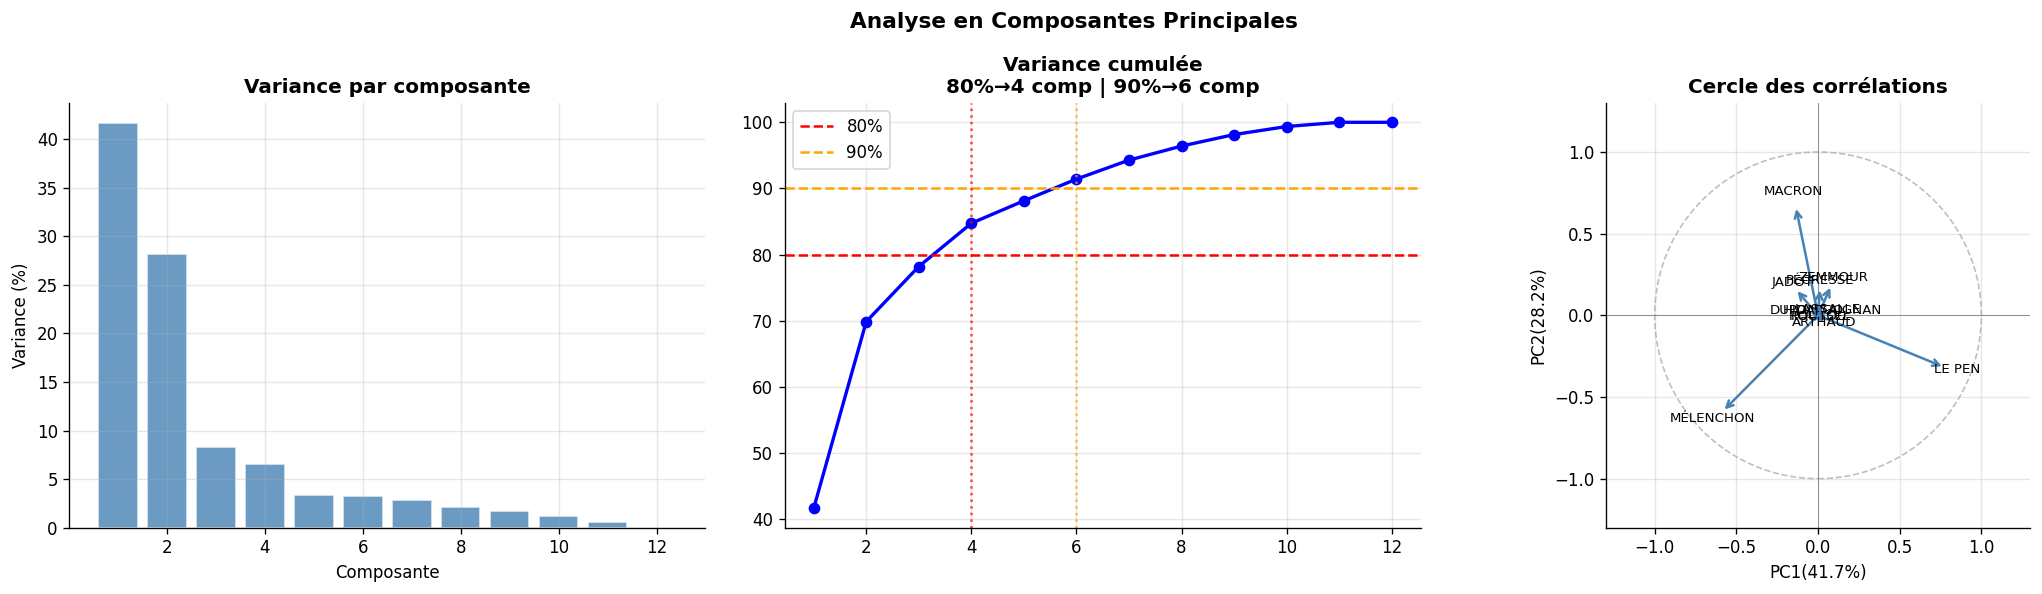

PC1+PC2 = 69.9%


In [6]:
pca_full = PCA()
pca_full.fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
k80 = np.argmax(cumvar >= 0.80)+1
k90 = np.argmax(cumvar >= 0.90)+1
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].bar(range(1,13), pca_full.explained_variance_ratio_*100,
            color='steelblue',edgecolor='white',alpha=0.8)
axes[0].set_xlabel("Composante"); axes[0].set_ylabel("Variance (%)")
axes[0].set_title("Variance par composante",fontweight='bold')
axes[1].plot(range(1,13), cumvar*100, 'bo-', lw=2)
axes[1].axhline(80,color='red',linestyle='--',label='80%')
axes[1].axhline(90,color='orange',linestyle='--',label='90%')
axes[1].axvline(k80,color='red',linestyle=':',alpha=0.7)
axes[1].axvline(k90,color='orange',linestyle=':',alpha=0.7)
axes[1].set_title(f"Variance cumulée\n80%→{k80} comp | 90%→{k90} comp",fontweight='bold')
axes[1].legend()
pca2v = PCA(n_components=2)
pca2v.fit(X_scaled)
ld = pca2v.components_.T
ax=axes[2]
for i,cand in enumerate(CANDS):
    nom=cand.split("_")[0]
    ax.annotate("",(ld[i,0],ld[i,1]),(0,0),arrowprops=dict(arrowstyle='->',color='steelblue',lw=1.5))
    ax.text(ld[i,0]*1.1,ld[i,1]*1.1,nom,fontsize=8,ha='center')
ax.add_patch(plt.Circle((0,0),1,fill=False,color='gray',linestyle='--',alpha=0.5))
ax.set_xlim(-1.3,1.3); ax.set_ylim(-1.3,1.3)
ax.axhline(0,color='gray',lw=0.5); ax.axvline(0,color='gray',lw=0.5)
ax.set_xlabel(f"PC1({pca2v.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2({pca2v.explained_variance_ratio_[1]*100:.1f}%)")
ax.set_title("Cercle des corrélations",fontweight='bold')
ax.set_aspect('equal')
plt.suptitle("Analyse en Composantes Principales",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()
print(f"PC1+PC2 = {pca2v.explained_variance_ratio_.sum()*100:.1f}%")


In [7]:
# KMeans sur ACP (espace réduit à k90 composantes)
pca_k = PCA(n_components=k90)
coords_k = pca_k.fit_transform(X_scaled)
print(f"ACP réduite : {coords_k.shape} — {pca_k.explained_variance_ratio_.sum()*100:.1f}% variance")
sil_pca = []
for k in range(2,11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    s  = silhouette_score(coords_k, km.fit_predict(coords_k), sample_size=5000)
    sil_pca.append(s)
best_k_pca = list(range(2,11))[sil_pca.index(max(sil_pca))]
print(f"k optimal sur ACP : {best_k_pca} (silhouette={max(sil_pca):.3f})")
print("Silhouettes ACP k=2 à 10 :")
for k,s in zip(range(2,11),sil_pca):
    print(f"  k={k} : {s:.3f}")

ACP réduite : (68770, 6) — 91.4% variance
k optimal sur ACP : 3 (silhouette=0.295)
Silhouettes ACP k=2 à 10 :
  k=2 : 0.273
  k=3 : 0.295
  k=4 : 0.223
  k=5 : 0.209
  k=6 : 0.205
  k=7 : 0.207
  k=8 : 0.211
  k=9 : 0.201
  k=10 : 0.199


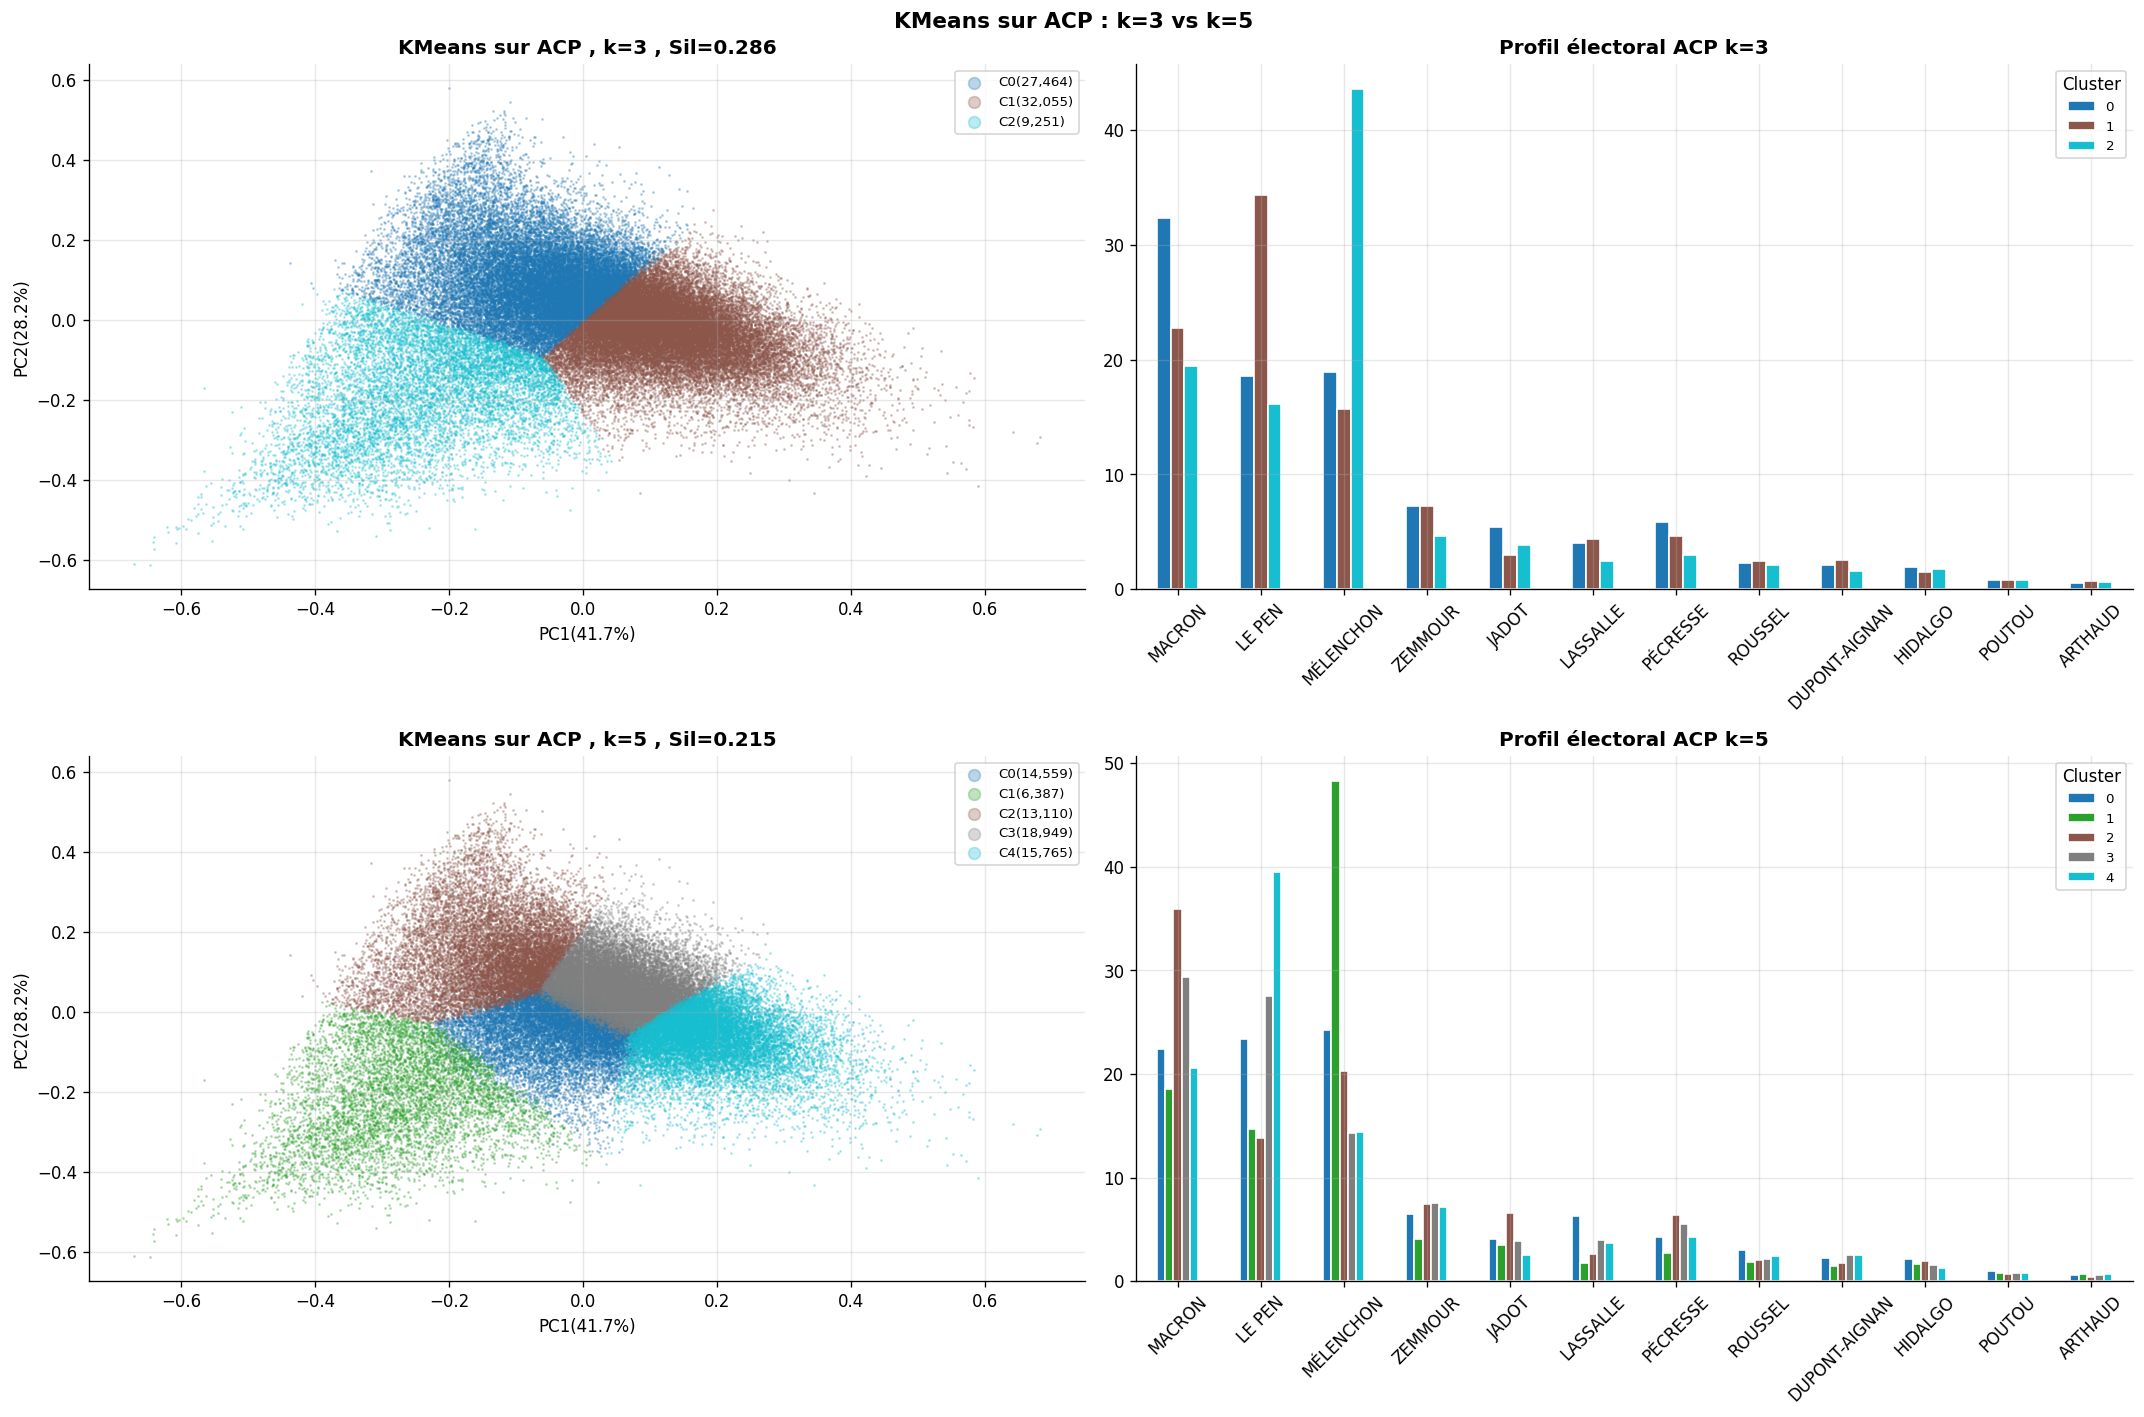

In [8]:
# Visualisation KMeans sur ACP k=3 et k=5
pca2_viz = PCA(n_components=2)
c2 = pca2_viz.fit_transform(X_scaled)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for row_idx, k in enumerate([3, 5]):
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(coords_k)
    sil = silhouette_score(coords_k, lbl, sample_size=5000)
    pal = plt.cm.tab10(np.linspace(0,1,k))
    final_df[f"cluster_acp_k{k}"] = lbl
    ax=axes[row_idx,0]
    for cl in range(k):
        m=lbl==cl
        ax.scatter(c2[m,0],c2[m,1],c=[pal[cl]],s=0.5,alpha=0.3,label=f"C{cl}({m.sum():,})")
    ax.set_xlabel(f"PC1({pca2_viz.explained_variance_ratio_[0]*100:.1f}%)")
    ax.set_ylabel(f"PC2({pca2_viz.explained_variance_ratio_[1]*100:.1f}%)")
    ax.set_title(f"KMeans sur ACP , k={k} , Sil={sil:.3f}",fontweight='bold')
    ax.legend(markerscale=10,fontsize=8)
    ax2=axes[row_idx,1]
    tmp=final_df.copy(); tmp["_cl"]=lbl
    prof=tmp.groupby("_cl")[CANDS].mean()
    prof.columns=[c.split("_")[0] for c in prof.columns]
    prof.T.plot(kind='bar',ax=ax2,colormap='tab10',edgecolor='white')
    ax2.set_title(f"Profil électoral ACP k={k}",fontweight='bold')
    ax2.tick_params(axis='x',rotation=45)
    ax2.legend(title="Cluster",bbox_to_anchor=(1,1),fontsize=8)
plt.suptitle("KMeans sur ACP : k=3 vs k=5",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()


## 4. UMAP Réduction non-linéaire

In [9]:
!pip install umap-learn -q
import umap
if "umap1" in final_df.columns:
    embedding = final_df[["umap1","umap2"]].values
    print(f"Embedding UMAP déjà disponible : {embedding.shape}")
else:
    print("Calcul UMAP...")
    reducer = umap.UMAP(n_components=2,n_neighbors=30,min_dist=0.1,
                        metric='euclidean',random_state=42,verbose=True)
    embedding = reducer.fit_transform(X_scaled)
    final_df["umap1"]=embedding[:,0]; final_df["umap2"]=embedding[:,1]
    print(f"UMAP calculé : {embedding.shape}")

Calcul UMAP...
UMAP(n_jobs=1, n_neighbors=30, random_state=42, verbose=True)
Sun Aug  9 12:46:16 2026 Construct fuzzy simplicial set
Sun Aug  9 12:46:17 2026 Finding Nearest Neighbors
Sun Aug  9 12:46:17 2026 Building RP forest with 18 trees
Sun Aug  9 12:46:25 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	Stopping threshold met -- exiting after 2 iterations
Sun Aug  9 12:46:51 2026 Finished Nearest Neighbor Search
Sun Aug  9 12:46:58 2026 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Sun Aug  9 12:48:25 2026 Finished embedding
UMAP calculé : (68770, 2)


In [10]:
# KMeans sur UMAP k=3 à 8
sil_umap, K_range_umap = [], range(3,9)
print("KMeans sur UMAP :")
for k in K_range_umap:
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(embedding)
    s   = silhouette_score(embedding, lbl, sample_size=5000)
    sil_umap.append(s)
    sizes=sorted(pd.Series(lbl).value_counts().tolist(),reverse=True)
    print(f"  k={k} : sil={s:.3f}  tailles={sizes}")
best_k_umap=list(K_range_umap)[sil_umap.index(max(sil_umap))]
print(f"k optimal UMAP : {best_k_umap} (sil={max(sil_umap):.3f})")

KMeans sur UMAP :
  k=3 : sil=0.423  tailles=[29773, 22865, 16132]
  k=4 : sil=0.395  tailles=[24224, 18249, 14627, 11670]
  k=5 : sil=0.417  tailles=[17570, 14885, 13543, 13507, 9265]
  k=6 : sil=0.403  tailles=[16715, 13640, 13386, 9554, 8821, 6654]
  k=7 : sil=0.381  tailles=[12461, 11802, 11312, 10653, 8124, 7903, 6515]
  k=8 : sil=0.371  tailles=[10531, 10075, 9849, 9163, 8482, 7829, 6578, 6263]
k optimal UMAP : 3 (sil=0.423)


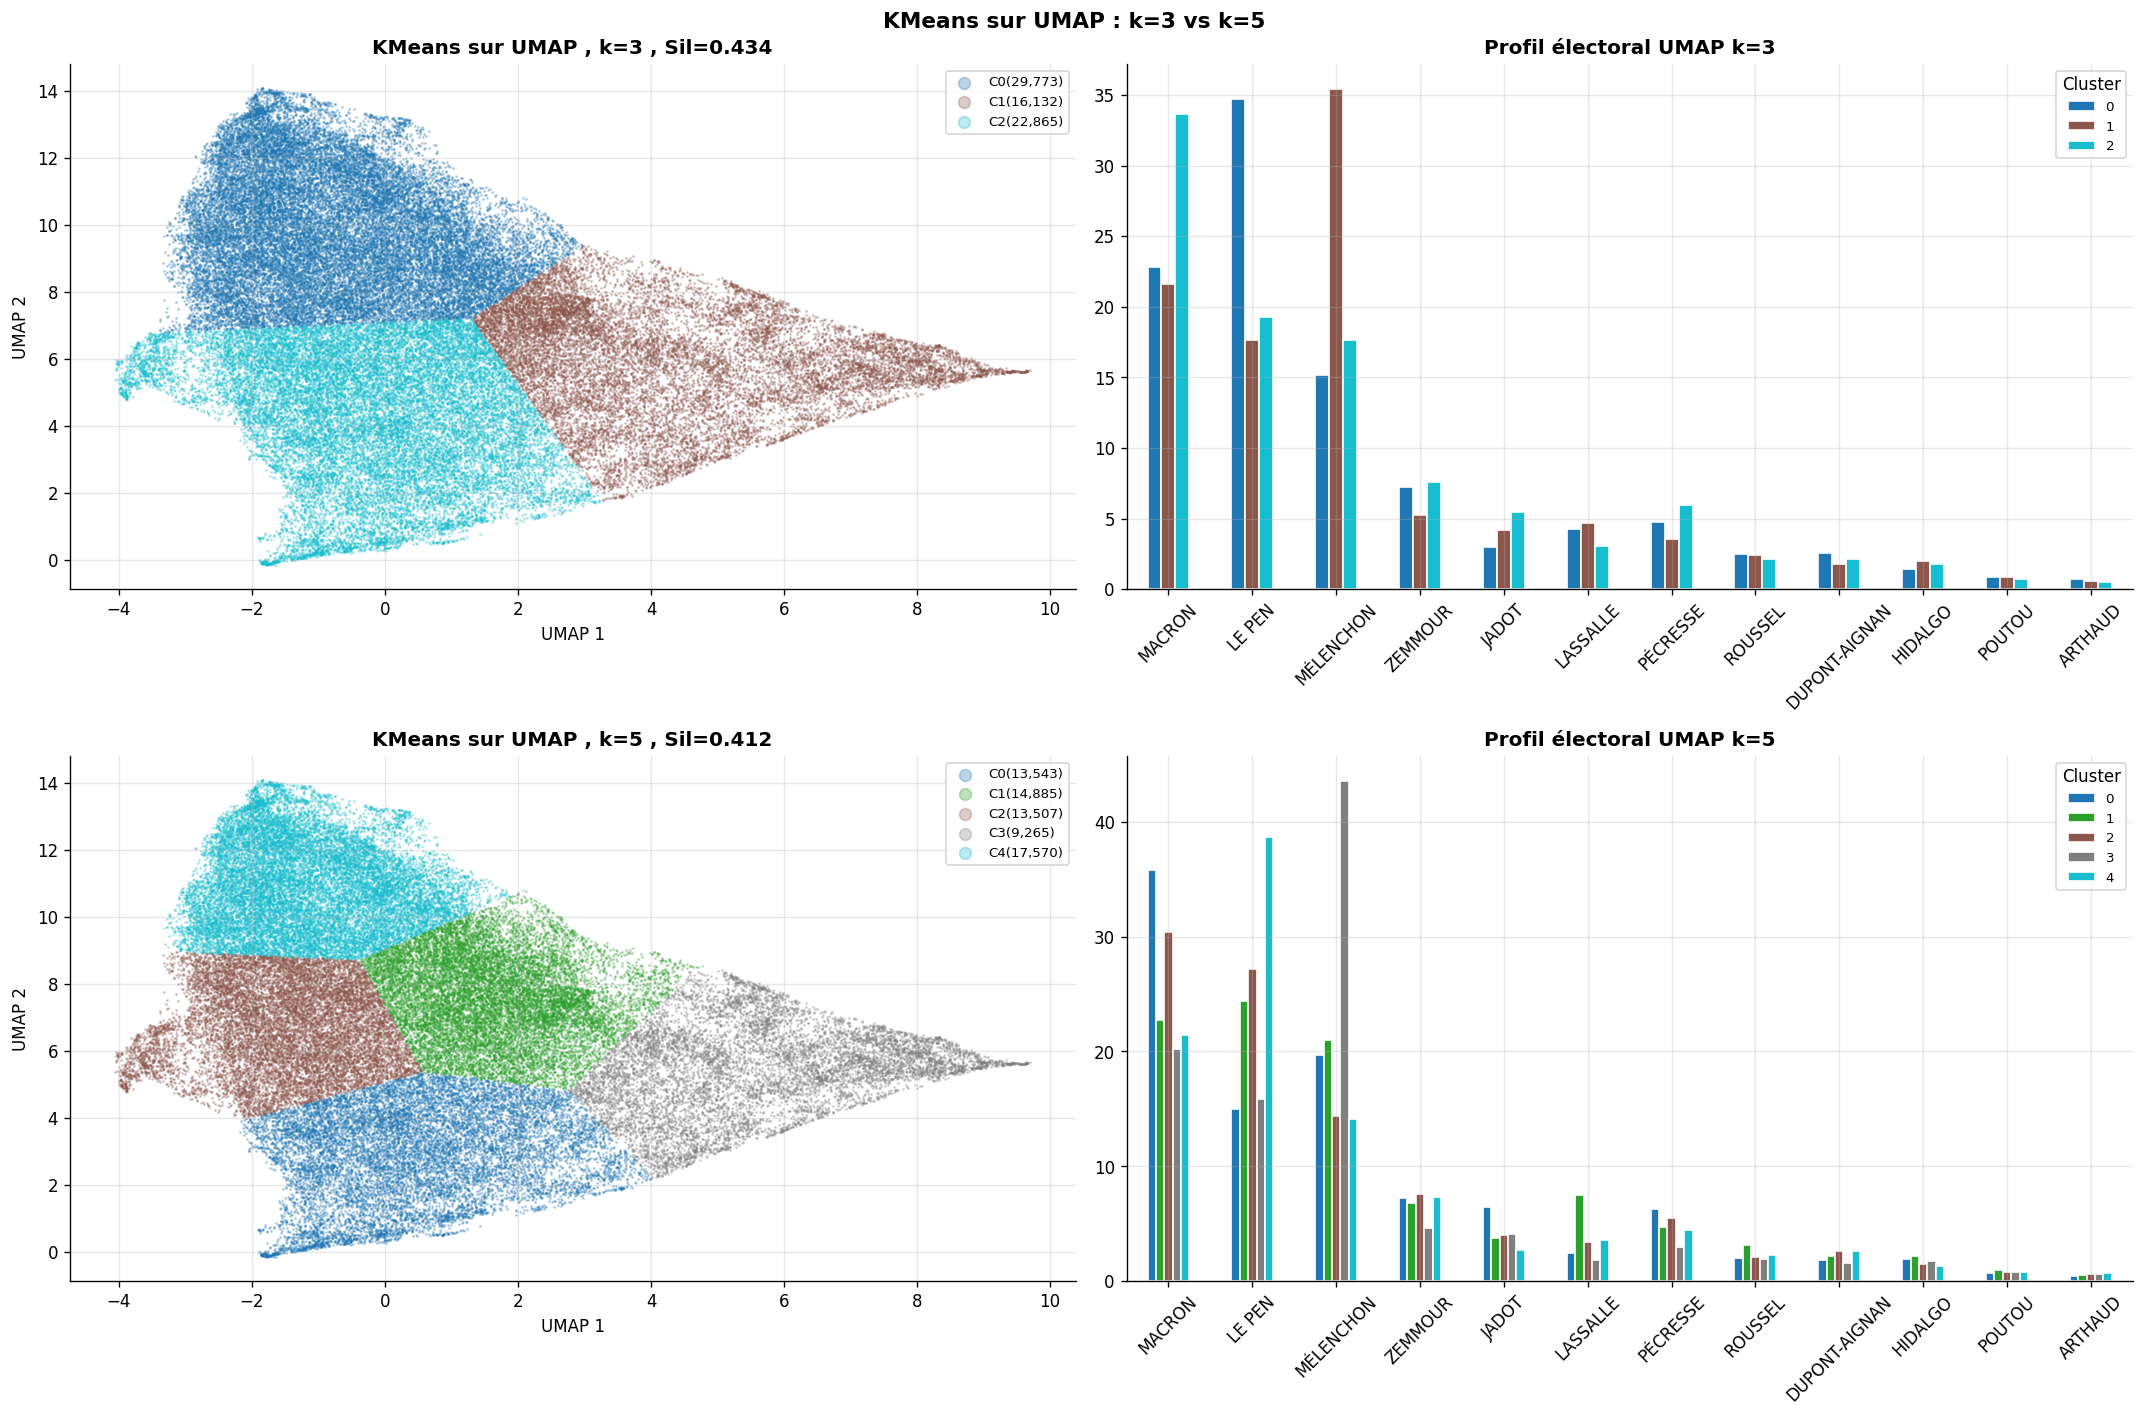

In [11]:
# Visualisation UMAP k=3 et k=5
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
for row_idx, k in enumerate([3, 5]):
    km  = KMeans(n_clusters=k, random_state=42, n_init=10)
    lbl = km.fit_predict(embedding)
    sil = silhouette_score(embedding, lbl, sample_size=5000)
    pal = plt.cm.tab10(np.linspace(0,1,k))
    final_df[f"cluster_umap_k{k}"] = lbl
    ax=axes[row_idx,0]
    for cl in range(k):
        m=lbl==cl
        ax.scatter(embedding[m,0],embedding[m,1],c=[pal[cl]],s=0.5,alpha=0.3,label=f"C{cl}({m.sum():,})")
    ax.set_xlabel("UMAP 1"); ax.set_ylabel("UMAP 2")
    ax.set_title(f"KMeans sur UMAP , k={k} , Sil={sil:.3f}",fontweight='bold')
    ax.legend(markerscale=10,fontsize=8)
    ax2=axes[row_idx,1]
    tmp=final_df.copy(); tmp["_cl"]=lbl
    prof=tmp.groupby("_cl")[CANDS].mean()
    prof.columns=[c.split("_")[0] for c in prof.columns]
    prof.T.plot(kind='bar',ax=ax2,colormap='tab10',edgecolor='white')
    ax2.set_title(f"Profil électoral UMAP k={k}",fontweight='bold')
    ax2.tick_params(axis='x',rotation=45)
    ax2.legend(title="Cluster",bbox_to_anchor=(1,1),fontsize=8)
plt.suptitle("KMeans sur UMAP : k=3 vs k=5",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()


## 5. Spectral Clustering
> Vecteurs propres du Graph Laplacian pour éviter la matrice n×n = 37 GB

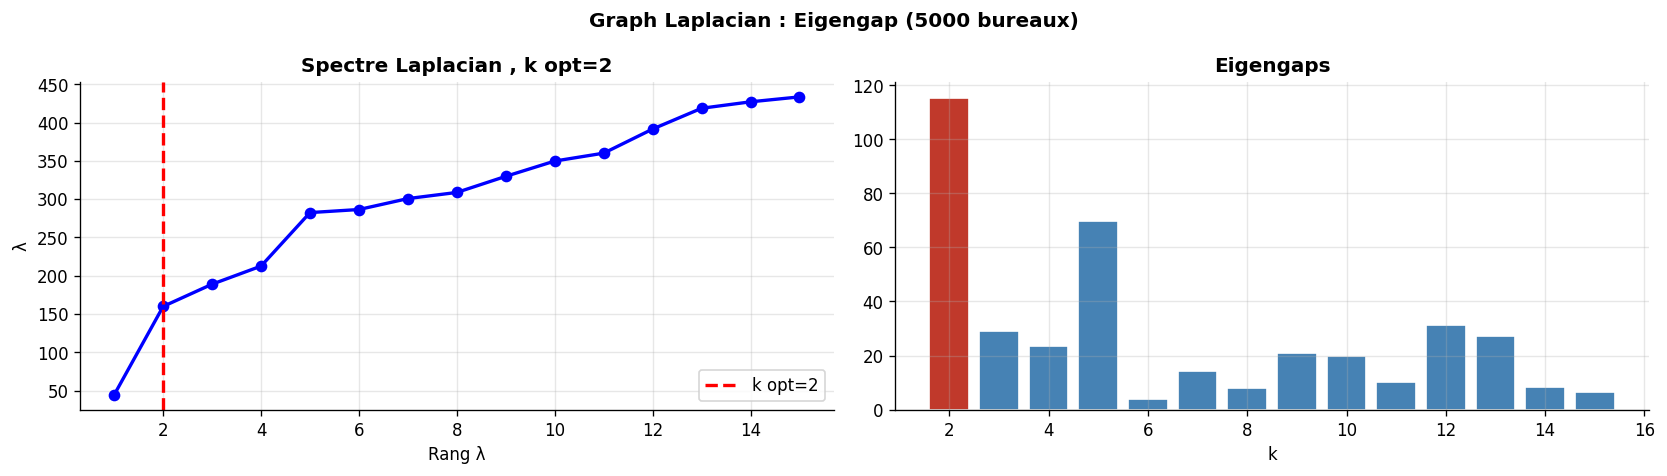

k optimal eigengap : 2


In [12]:
# Graph Laplacian sur 5000 bureaux
np.random.seed(42)
N_S = 5000
sidx  = np.random.choice(len(X_scaled), size=N_S, replace=False)
Xs    = X_scaled[sidx]
D     = pairwise_distances(Xs, metric='euclidean')
sig   = np.median(D)
A     = np.exp(-D**2/(2*sig**2)); np.fill_diagonal(A,0)
L     = np.diag(A.sum(axis=1)) - A
ev, evec = np.linalg.eigh(L)
ev_s  = np.sort(ev)
evec  = evec[:,np.argsort(ev)]
gaps  = np.diff(ev_s[1:16])
k_opt = gaps.argmax()+2
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(range(1,16),ev_s[1:16],'bo-',lw=2)
axes[0].axvline(k_opt,color='red',linestyle='--',lw=2,label=f'k opt={k_opt}')
axes[0].set_title(f"Spectre Laplacian , k opt={k_opt}",fontweight='bold')
axes[0].set_xlabel("Rang λ"); axes[0].set_ylabel("λ"); axes[0].legend()
axes[1].bar(range(2,16),gaps,
            color=['#C0392B' if i+2==k_opt else 'steelblue' for i in range(14)],edgecolor='white')
axes[1].set_title("Eigengaps",fontweight='bold'); axes[1].set_xlabel("k")
plt.suptitle("Graph Laplacian : Eigengap (5000 bureaux)",fontweight='bold')
plt.tight_layout(); plt.show()
print(f"k optimal eigengap : {k_opt}")

Spectral Clustering (vecteurs propres) :
  k=2 : sil=0.974  tailles=[4985, 15]
  k=3 : sil=0.902  tailles=[4947, 41, 12]
  k=5 : sil=0.731  tailles=[4480, 293, 116, 96, 15]


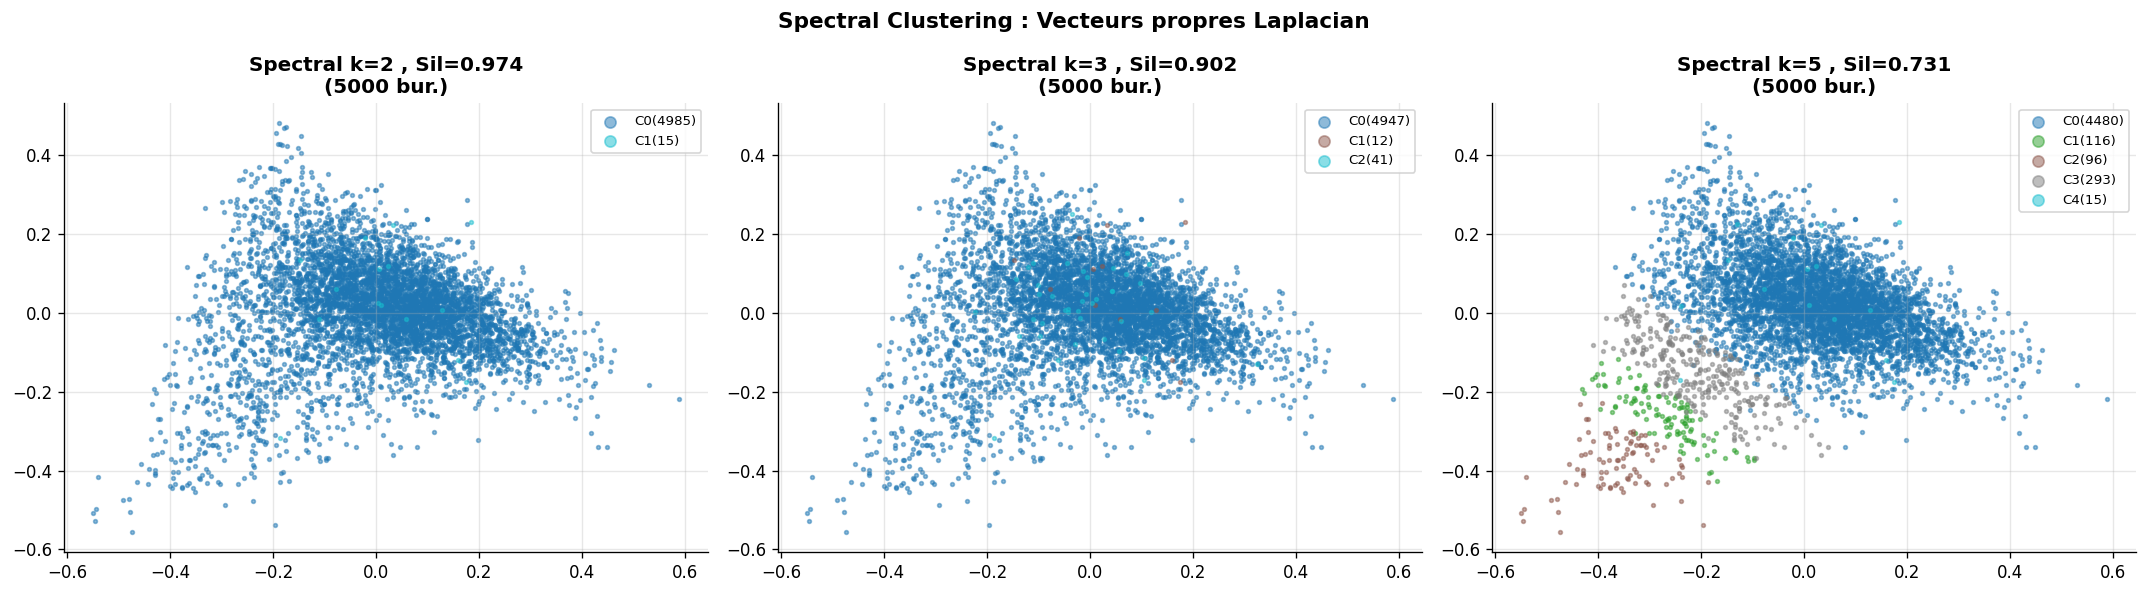

In [13]:
# Spectral sur l'échantillon via vecteurs propres
results_sp = {}
print("Spectral Clustering (vecteurs propres) :")
pca_s = PCA(n_components=2)
c_s   = pca_s.fit_transform(Xs)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax_idx, k in enumerate([2, 3, 5]):
    emb_sp = evec[:,1:k+1]
    norms  = np.linalg.norm(emb_sp,axis=1,keepdims=True)
    emb_n  = emb_sp/(norms+1e-10)
    km_sp  = KMeans(n_clusters=k, random_state=42, n_init=20)
    lbl_sp = km_sp.fit_predict(emb_n)
    sil_sp = silhouette_score(emb_n, lbl_sp)
    results_sp[k] = {"labels":lbl_sp,"silhouette":sil_sp}
    sizes = sorted(pd.Series(lbl_sp).value_counts().tolist(),reverse=True)
    print(f"  k={k} : sil={sil_sp:.3f}  tailles={sizes}")
    pal=plt.cm.tab10(np.linspace(0,1,k))
    ax=axes[ax_idx]
    for cl in range(k):
        m=lbl_sp==cl
        ax.scatter(c_s[m,0],c_s[m,1],c=[pal[cl]],s=5,alpha=0.5,label=f"C{cl}({m.sum()})")
    ax.set_title(f"Spectral k={k} , Sil={sil_sp:.3f}\n(5000 bur.)",fontweight='bold')
    ax.legend(markerscale=3,fontsize=8)
plt.suptitle("Spectral Clustering : Vecteurs propres Laplacian",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()


## 6. Comparaison toutes méthodes

In [14]:
# Cohérence entre méthodes (ARI k=5)
cols_k5 = [c for c in final_df.columns if 'cluster' in c and 'k5' in c]
print(f"Colonnes k=5 : {cols_k5}")
print("\nARI entre méthodes (k=5) :")
for i,c1 in enumerate(cols_k5):
    for j,c2 in enumerate(cols_k5):
        if i<j:
            ari = adjusted_rand_score(final_df[c1],final_df[c2])
            nmi = normalized_mutual_info_score(final_df[c1],final_df[c2])
            print(f"  {c1.replace('cluster_',''):<25} ↔ {c2.replace('cluster_',''):<25} ARI={ari:.3f} NMI={nmi:.3f}")

Colonnes k=5 : ['cluster_kmeans_k5', 'cluster_acp_k5', 'cluster_umap_k5']

ARI entre méthodes (k=5) :
  kmeans_k5                 ↔ acp_k5                    ARI=0.968 NMI=0.952
  kmeans_k5                 ↔ umap_k5                   ARI=0.631 NMI=0.655
  acp_k5                    ↔ umap_k5                   ARI=0.639 NMI=0.659



## 7. Clustering final retenu : k=5 sur UMAP


Clustering final : KMeans UMAP k=5 , Sil=0.420
cluster_final_k5
0    13543
1    14885
2    13507
3     9265
4    17570
Name: count, dtype: int64


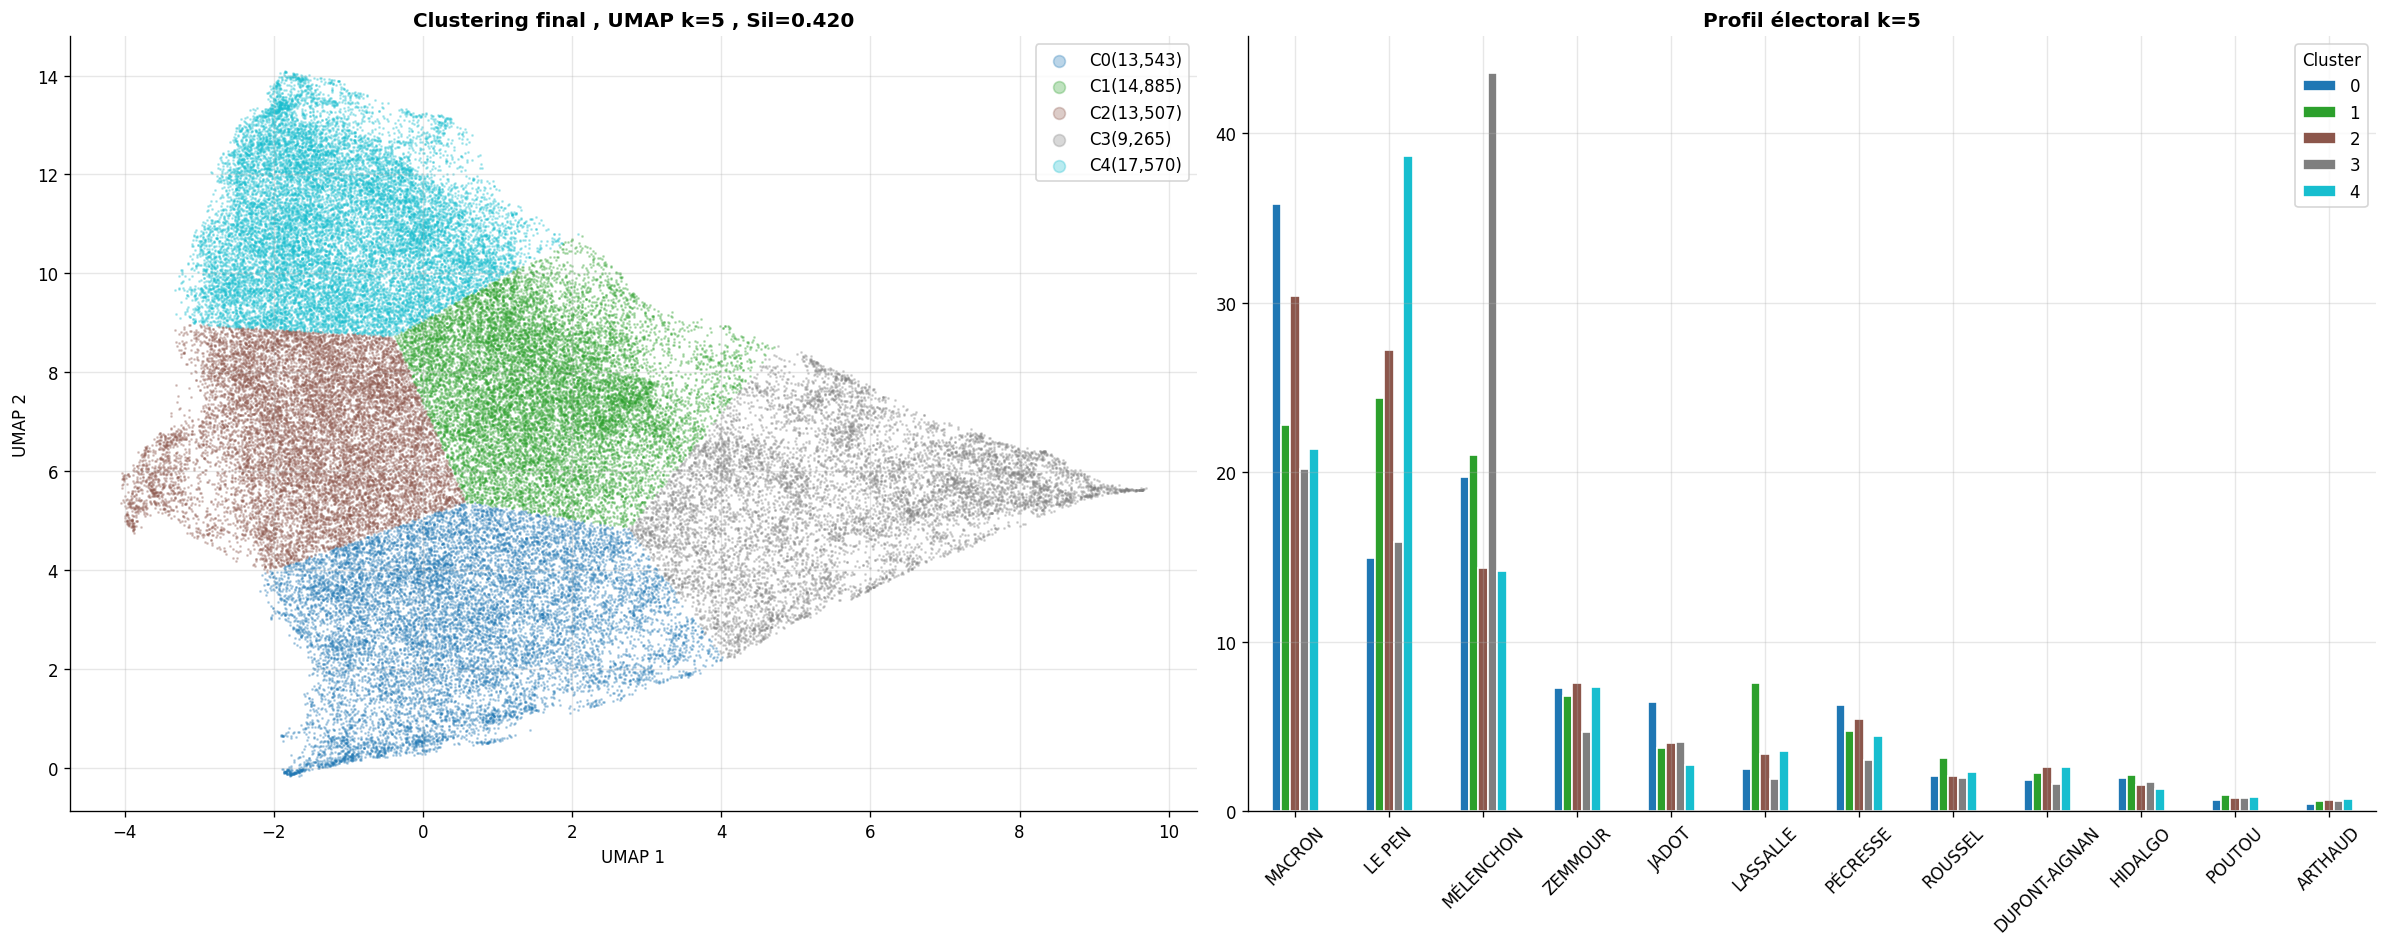

In [15]:
K_FINAL = 5
km_f = KMeans(n_clusters=K_FINAL, random_state=42, n_init=10)
lbl_f = km_f.fit_predict(embedding)
sil_f = silhouette_score(embedding, lbl_f, sample_size=5000)
final_df["cluster_final_k5"] = lbl_f
print(f"Clustering final : KMeans UMAP k={K_FINAL} , Sil={sil_f:.3f}")
print(final_df["cluster_final_k5"].value_counts().sort_index())
pal=plt.cm.tab10(np.linspace(0,1,K_FINAL))
fig,axes=plt.subplots(1,2,figsize=(20,8))
for cl in range(K_FINAL):
    m=lbl_f==cl
    axes[0].scatter(embedding[m,0],embedding[m,1],c=[pal[cl]],s=0.5,alpha=0.3,label=f"C{cl}({m.sum():,})")
axes[0].set_xlabel("UMAP 1"); axes[0].set_ylabel("UMAP 2")
axes[0].set_title(f"Clustering final , UMAP k=5 , Sil={sil_f:.3f}",fontweight='bold')
axes[0].legend(markerscale=10)
tmp=final_df.copy(); tmp["_cl"]=lbl_f
prof_f=tmp.groupby("_cl")[CANDS].mean()
prof_f.columns=[c.split("_")[0] for c in prof_f.columns]
prof_f.T.plot(kind='bar',ax=axes[1],colormap='tab10',edgecolor='white')
axes[1].set_title("Profil électoral k=5",fontweight='bold')
axes[1].tick_params(axis='x',rotation=45)
axes[1].legend(title="Cluster",bbox_to_anchor=(1,1))
plt.tight_layout(); plt.show()

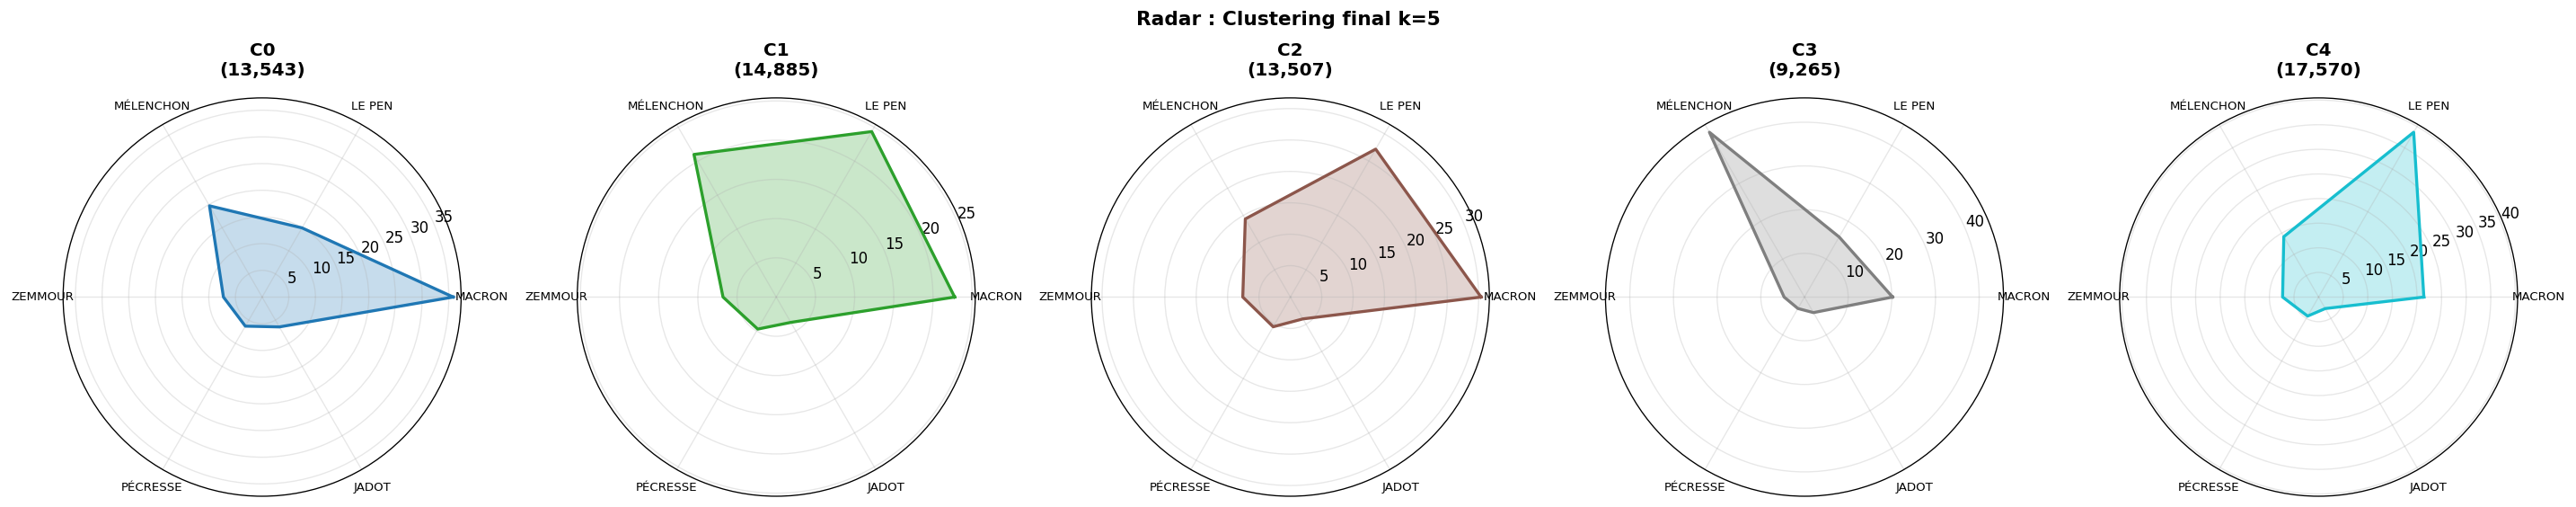

In [16]:
# Radar k=5
top6=sorted(CANDS,key=lambda x:final_df[x].mean(),reverse=True)[:6]
labs=[c.split("_")[0] for c in top6]; N=len(labs)
ang=np.linspace(0,2*np.pi,N,endpoint=False).tolist()+[np.linspace(0,2*np.pi,N,endpoint=False)[0]]
fig,axes=plt.subplots(1,K_FINAL,figsize=(24,5),subplot_kw=dict(polar=True))
pal=plt.cm.tab10(np.linspace(0,1,K_FINAL))
for cl in range(K_FINAL):
    ax=axes[cl]; vals=prof_f.loc[cl,labs].values.tolist()+[prof_f.loc[cl,labs[0]]]
    ax.plot(ang,vals,color=pal[cl],lw=2); ax.fill(ang,vals,color=pal[cl],alpha=0.25)
    ax.set_xticks(ang[:-1]); ax.set_xticklabels(labs,size=8)
    n_bv=(lbl_f==cl).sum()
    ax.set_title(f"C{cl}\n({n_bv:,})",fontweight='bold',pad=15)
plt.suptitle("Radar : Clustering final k=5",fontsize=13,fontweight='bold')
plt.tight_layout(); plt.show()

In [17]:
# Caractérisation finale k=5
print("="*65); print("CLUSTERING FINAL k=5 avec UMAP"); print("="*65)
for cl in range(K_FINAL):
    subset=final_df[lbl_f==cl]; n=len(subset)
    top3=prof_f.loc[cl].sort_values(ascending=False).head(3)
    t3=", ".join([f"{c}({v:.1f}%)" for c,v in top3.items()])
    part=subset["% Vot/Ins"].mean() if "% Vot/Ins" in subset.columns else "?"
    ins=subset["Inscrits"].mean() if "Inscrits" in subset.columns else "?"
    deps=subset["Libellé du département"].value_counts().head(3).index.tolist() if "Libellé du département" in subset.columns else []
    print(f"\n C{cl} ({n:,}, {n/len(final_df)*100:.1f}%) ")
    print(f"  Top 3 : {t3}")
    if part!="?": print(f"  Particip={part:.1f}%  Inscrits/bur={ins:.0f}")
    print(f"  Dépts : {', '.join(deps)}")

CLUSTERING FINAL k=5 avec UMAP

 C0 (13,543, 19.7%) 
  Top 3 : MACRON(35.8%), MÉLENCHON(19.7%), LE PEN(15.0%)
  Particip=79.0%  Inscrits/bur=905
  Dépts : Hauts-de-Seine, Yvelines, Loire-Atlantique

 C1 (14,885, 21.6%) 
  Top 3 : LE PEN(24.4%), MACRON(22.8%), MÉLENCHON(21.0%)
  Particip=77.9%  Inscrits/bur=553
  Dépts : Pyrénées-Atlantiques, Haute-Garonne, Hautes-Pyrénées

 C2 (13,507, 19.6%) 
  Top 3 : MACRON(30.4%), LE PEN(27.2%), MÉLENCHON(14.4%)
  Particip=78.5%  Inscrits/bur=658
  Dépts : Alpes-Maritimes, Nord, Bas-Rhin

 C3 (9,265, 13.5%) 
  Top 3 : MÉLENCHON(43.5%), MACRON(20.2%), LE PEN(15.9%)
  Particip=66.7%  Inscrits/bur=884
  Dépts : La Réunion, Seine-Saint-Denis, Val-de-Marne

 C4 (17,570, 25.5%) 
  Top 3 : LE PEN(38.7%), MACRON(21.4%), MÉLENCHON(14.2%)
  Particip=76.9%  Inscrits/bur=527
  Dépts : Pas-de-Calais, Nord, Aisne



## 8. Export

In [20]:
output_path = BASE + "resultats_t1_bureaux_clusters_K5.csv"
final_df.to_csv(output_path, index=False)
print(f"Base exportée : {output_path}")
print(f"Dimensions : {final_df.shape}")

Base exportée : /content/drive/MyDrive/Stage/resultats_t1_bureaux_clusters_K5.csv
Dimensions : (68770, 29)


In [19]:
# ── Caractérisation socio-économique des 5 clusters ─────────────
# Les clusters ont été construits uniquement à partir des scores électoraux

socio = pd.read_csv(BASE + "base_finale_bureaux.csv", dtype={"id_bv": str})

X_COLS = [
    "taux_chomage", "part_voiture", "part_tcom", "part_diplmin",
    "part_bac2", "part_bac34", "part_bac5plus", "DISP_MED21",
]

# Jointure des labels de cluster (final_df) avec les variables socio-éco
cluster_socio = final_df[["id_bv", "cluster_final_k5"]].merge(
    socio[["id_bv"] + X_COLS], on="id_bv", how="inner"
)
print(f"Bureaux avec cluster ET profil socio-économique : {len(cluster_socio):,} "
      f"/ {len(final_df):,}")

# Moyenne des variables socio-économiques par cluster
profil_socio_cluster = cluster_socio.groupby("cluster_final_k5")[X_COLS].mean().round(3)
profil_socio_cluster.index = [f"C{i}" for i in profil_socio_cluster.index]

print("\nProfil socio-économique moyen par cluster :")
print(profil_socio_cluster.to_string())

# Moyenne nationale pour comparaison (permet de voir si un cluster est
# au-dessus ou en-dessous de la moyenne, colonne par colonne)
moyenne_nationale = cluster_socio[X_COLS].mean().round(3)
print("\nMoyenne nationale (référence) :")
print(moyenne_nationale.to_string())

Bureaux avec cluster ET profil socio-économique : 68,770 / 68,770

Profil socio-économique moyen par cluster :
    taux_chomage  part_voiture  part_tcom  part_diplmin  part_bac2  part_bac34  part_bac5plus  DISP_MED21
C0         0.092         0.659      0.165         0.061      0.155       0.152          0.238   27109.402
C1         0.107         0.816      0.044         0.085      0.152       0.112          0.093   22011.704
C2         0.086         0.834      0.040         0.079      0.160       0.114          0.102   24119.467
C3         0.149         0.567      0.257         0.126      0.129       0.128          0.167   21240.315
C4         0.106         0.859      0.032         0.102      0.145       0.092          0.066   22367.488

Moyenne nationale (référence) :
taux_chomage         0.105
part_voiture         0.766
part_tcom            0.092
part_diplmin         0.089
part_bac2            0.149
part_bac34           0.117
part_bac5plus        0.127
DISP_MED21       23416.559
